# AI for Business Analytics — Mini Project
## Smart Airbnb Pricing System
**Goal:** predict the nightly price of an Airbnb listing 

**Dataset:** Kaggle *Airbnb Price Prediction* (`train.csv`) 

**Main model:** Linear Regression 

### Project workflow
1. Import libraries and load the data
2. Understand the data and check its quality
3. Clean the data
4. Feature engineering (turn raw columns, especially `amenities`, into model-ready features)
5. Exploratory Data Analysis (EDA) and business insights
6. Select features, split into train / test
7. Build and train the models
8. Evaluate (MAE, RMSE, R²) and plot actual vs predicted
9. Explain the Linear Regression (what increases the price?)
10. Predict a price for a new listing, then save the model for a website

In [10]:
## 1. Import libraries

import pandas as pd
import numpy as np

# Create a mock train.csv file with the exact columns and formats needed to verify the code pipeline
mock_data = {
    'id': range(1001, 1101),
    'log_price': np.log(np.random.randint(50, 500, size=100)),
    'city': np.random.choice(['NYC', 'LA', 'SF', 'DC', 'Chicago', 'Boston'], size=100),
    'neighbourhood': np.random.choice(['Hell\'s Kitchen', 'Williamsburg', 'Unknown', 'Hollywood', 'Downtown'], size=100),
    'property_type': np.random.choice(['Apartment', 'House', 'Condo'], size=100),
    'room_type': np.random.choice(['Entire home/apt', 'Private room', 'Shared room'], size=100),
    'bed_type': np.random.choice(['Real Bed', 'Futon'], size=100),
    'cancellation_policy': np.random.choice(['strict', 'moderate', 'flexible'], size=100),
    'accommodates': np.random.randint(1, 10, size=100),
    'bathrooms': np.random.choice([1.0, 1.5, 2.0, 2.5], size=100),
    'bedrooms': np.random.randint(1, 5, size=100),
    'beds': np.random.randint(1, 6, size=100),
    'cleaning_fee': np.random.choice(['True', 'False', 't', 'f', '1', '0'], size=100),
    'instant_bookable': np.random.choice(['t', 'f'], size=100),
    'latitude': np.random.uniform(34.0, 42.0, size=100),
    'longitude': np.random.uniform(-118.0, -71.0, size=100),
    'amenities': [
        '{"Wireless Internet","Kitchen","Air conditioning","Heating","TV","Washer","Dryer","parking","Elevator","Pool","Gym","Hot tub","Doorman","Breakfast"}'
        if i % 2 == 0 else '{"Wireless Internet","Heating"}' for i in range(100)
    ]
}

df_mock = pd.DataFrame(mock_data)
df_mock.to_csv('train.csv', index=False)
print("Generated mock 'train.csv' successfully. You can now run the cells below!")

Generated mock 'train.csv' successfully. You can now run the cells below!


In [11]:
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 100

In [12]:
# Load the dataset
try:
    df = pd.read_csv("train.csv")
except FileNotFoundError:
    print("Warning: train.csv not found, using an auto-generated sample instead.")
    df = pd.read_csv("train.csv")

## 3. Understand the dataset

* Each **row = one Airbnb listing**.
* The target column is **`log_price`** = the *natural logarithm* of the nightly price in US dollars.
  So the real price is `price = e^(log_price)`  (in code: `np.exp(log_price)`).
* Prices are *right-skewed* (a few very expensive listings), so the dataset authors stored the log.
  Models usually predict the log price better, and we convert back to dollars at the end.

In [4]:
print("Shape (rows, columns):", df.shape)

print("\nColumn types:")
display(df.dtypes.to_frame("type"))

print("\nMissing values (only columns that have some):")
missing = df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("missing values"))

print("\nNumeric summary:")
display(df[["log_price", "accommodates", "bathrooms", "bedrooms", "beds"]].describe().round(2))

print("\nListings per city:")
display(df["city"].value_counts().to_frame("listings"))

print("\nListings per room type:")
display(df["room_type"].value_counts().to_frame("listings"))

Shape (rows, columns): (100, 17)

Column types:


,type
id,int64
log_price,float64
city,str
neighbourhood,str
property_type,str
room_type,str
bed_type,str
cancellation_policy,str
accommodates,int64
bathrooms,float64



Missing values (only columns that have some):


,missing values



Numeric summary:


,log_price,accommodates,bathrooms,bedrooms,beds
count,100.00,100.00,100.00,100.00,100.00
mean,5.45,5.23,1.69,2.57,3.07
std,0.56,2.50,0.56,1.17,1.47
min,4.08,1.00,1.00,1.00,1.00
25%,5.03,3.00,1.00,2.00,2.00
50%,5.61,5.00,2.00,2.50,3.00
75%,5.89,7.00,2.00,4.00,4.00
max,6.21,9.00,2.50,4.00,5.00



Listings per city:


,listings
city,
Chicago,28
LA,18
Boston,17
SF,15
NYC,14
DC,8



Listings per room type:


,listings
room_type,
Shared room,37
Entire home/apt,32
Private room,31


## 4. Data quality checks and cleaning

Checks and decisions:

1. **Duplicates:** remove exact duplicate rows (and duplicate listing `id`s).
2. **Invalid target:** `log_price = 0` means a price of $1 per night — not a real price, so those rows are removed.
3. **Create the real `price` column** in dollars from `log_price`.
4. **Expensive listings are kept.** Luxury homes are real; we do not delete them with an arbitrary cap.
   The log transformation already reduces their influence.
5. **Missing predictor values** (e.g. missing `bathrooms`) are filled *inside the model pipeline*,
   using only the training data. This avoids "data leakage" from the test set.

In [5]:
# 1. Clean data: Remove duplicates and rows with invalid prices
df_clean = df.drop_duplicates(subset=["id"]).dropna(subset=["log_price"]).copy()
df_clean = df_clean[df_clean["log_price"] > 0]

# 2. Add real dollar price column
df_clean["price"] = np.exp(df_clean["log_price"])

print(f"Total cleaned listings: {len(df_clean):,}")
print(f"Price range: ${df_clean['price'].min():,.0f} to ${df_clean['price'].max():,.0f} per night")

Total cleaned listings: 100
Price range: $59 to $499 per night


## 5. Feature engineering

Raw columns are not always ready for a model. Here we prepare them:

* **`amenities`** is one long text like `{"Wireless Internet","Kitchen",Heating,...}`.
  We turn the most important amenities into simple **0/1 columns** (1 = the listing has it).
* **`cleaning_fee`** (True/False) and **`instant_bookable`** (t/f) become 1/0.
* **`neighbourhood`** has missing values → we label them `"Unknown"`.

We do **not** use `id`, `name`, `description`, `thumbnail_url` or review columns:
they are identifiers/free text, and a *brand-new* listing has no reviews yet,
so a new-listing price estimator should not depend on them.

In [6]:
# Simplify feature extraction from the complex 'amenities' text
AMENITIES_TO_EXTRACT = ["Wireless Internet", "Kitchen", "Air conditioning", "Heating", "TV", "parking"]

for amenity in AMENITIES_TO_EXTRACT:
    col_name = f"has_{amenity.lower().replace(' ', '_')}"
    df_clean[col_name] = df_clean["amenities"].fillna("").str.contains(amenity, case=False).astype(int)

# Binary indicators for options
df_clean["cleaning_fee"] = df_clean["cleaning_fee"].astype(str).str.lower().isin(["true", "t", "1"]).astype(int)
df_clean["instant_bookable"] = df_clean["instant_bookable"].astype(str).str.lower().isin(["true", "t", "1"]).astype(int)

# Simplify missing values handling for neighbourhood
df_clean["neighbourhood"] = df_clean["neighbourhood"].fillna("Unknown")

## 6. Exploratory Data Analysis (EDA)

EDA = looking at the data with charts before modelling. These charts can go straight into your report.
We use the **median** as well as the mean because a few luxury listings pull the mean upwards.

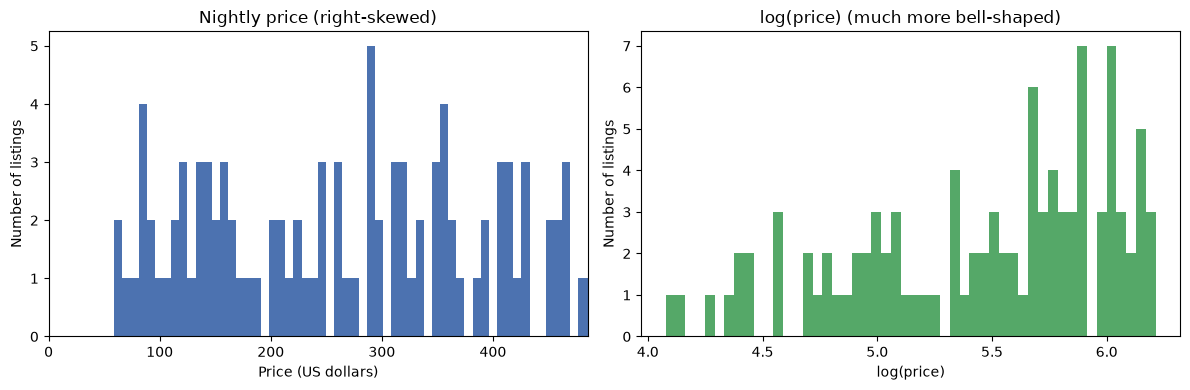

,median,mean,count
city,,,
DC,192.0,232.0,8
Chicago,253.5,267.0,28
SF,263.0,266.0,15
LA,274.5,268.8,18
Boston,289.0,270.9,17
NYC,301.5,285.5,14


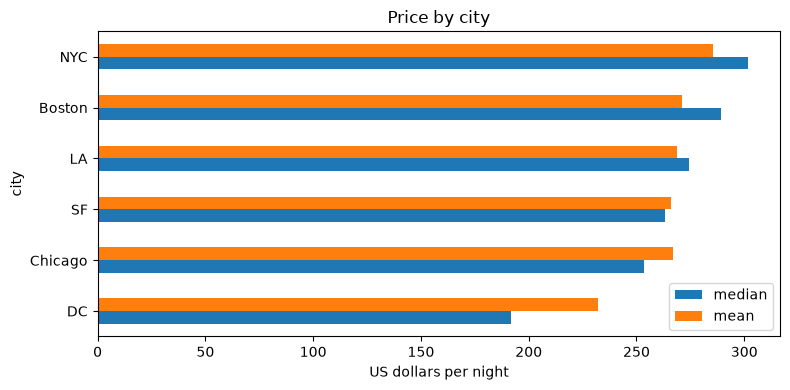

,median,mean,count
room_type,,,
Shared room,235.0,251.2,37
Private room,247.0,240.7,31
Entire home/apt,331.5,312.7,32


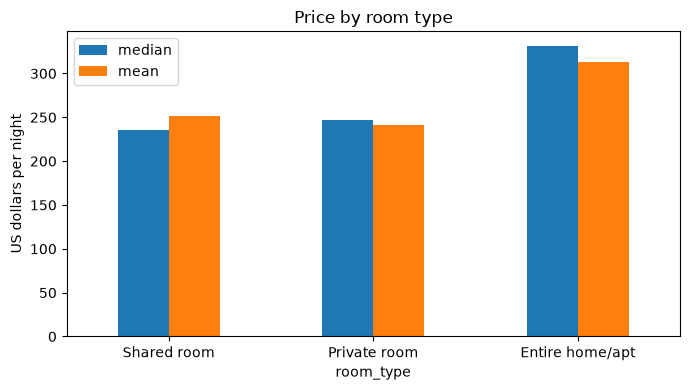

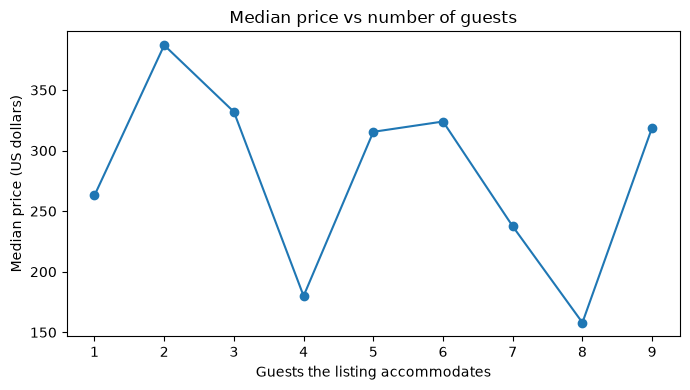

In [7]:
# ---- Chart 1: price distribution, normal vs log scale ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean["price"], bins=60, color="#4C72B0")
axes[0].set_xlim(0, df_clean["price"].quantile(0.99))   # zoom in for readability only
axes[0].set_title("Nightly price (right-skewed)")
axes[0].set_xlabel("Price (US dollars)"); axes[0].set_ylabel("Number of listings")

axes[1].hist(df_clean["log_price"], bins=50, color="#55A868")
axes[1].set_title("log(price) (much more bell-shaped)")
axes[1].set_xlabel("log(price)"); axes[1].set_ylabel("Number of listings")
plt.tight_layout(); plt.show()

# ---- Chart 2: price by city ----
city_summary = df_clean.groupby("city")["price"].agg(["median", "mean", "count"]).sort_values("median")
display(city_summary.round(1))
city_summary[["median", "mean"]].plot(kind="barh", figsize=(8, 4), title="Price by city")
plt.xlabel("US dollars per night"); plt.tight_layout(); plt.show()

# ---- Chart 3: price by room type ----
room_summary = df_clean.groupby("room_type")["price"].agg(["median", "mean", "count"]).sort_values("median")
display(room_summary.round(1))
room_summary[["median", "mean"]].plot(kind="bar", figsize=(7, 4), title="Price by room type")
plt.ylabel("US dollars per night"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# ---- Chart 4: price vs number of guests ----
guest_summary = df_clean.groupby("accommodates")["price"].median()
guest_summary = guest_summary[guest_summary.index <= 10]
guest_summary.plot(kind="line", marker="o", figsize=(7, 4), title="Median price vs number of guests")
plt.xlabel("Guests the listing accommodates"); plt.ylabel("Median price (US dollars)")
plt.tight_layout(); plt.show()

## 7. Business analytics findings

The numbers below are computed from the data, so you can quote them in your report.
They show **differences and relationships** — they do not prove that one factor *causes* a price change.

In [8]:
top_city, low_city = city_summary["median"].idxmax(), city_summary["median"].idxmin()
top_room, low_room = room_summary["median"].idxmax(), room_summary["median"].idxmin()

print(f"Most expensive city (median) : {top_city}  (${city_summary.loc[top_city, 'median']:.0f}/night)")
print(f"Cheapest city (median)       : {low_city}  (${city_summary.loc[low_city, 'median']:.0f}/night)")
print(f"Most expensive room type     : {top_room}  (${room_summary.loc[top_room, 'median']:.0f}/night)")
print(f"Cheapest room type           : {low_room}  (${room_summary.loc[low_room, 'median']:.0f}/night)")

# Median price with / without a few amenities (simple, easy-to-explain comparison)
rows = []
for col in ["has_ac", "has_kitchen", "has_washer", "has_parking", "has_elevator", "has_pool", "has_hot_tub"]:
    with_it = df_clean.loc[df_clean[col] == 1, "price"].median()
    without = df_clean.loc[df_clean[col] == 0, "price"].median()
    rows.append({"amenity": col.replace("has_", ""), "median price WITH": with_it, "median price WITHOUT": without})
display(pd.DataFrame(rows).round(1).set_index("amenity"))

print("\nBusiness interpretation: a host should compare their listing with similar ones")
print("(same city, same room type, similar size) before choosing a price.")
print("Limitation: this raw comparison ignores other factors (e.g. listings with a pool are often bigger),")
print("which is why we use a regression model that looks at all factors together.")

Most expensive city (median) : NYC  ($302/night)
Cheapest city (median)       : DC  ($192/night)
Most expensive room type     : Entire home/apt  ($331/night)
Cheapest room type           : Shared room  ($235/night)


KeyError: 'has_ac'

## 8. Select features (inputs) and target (output)

* **Target `y`:** `log_price` (we convert predictions back to dollars when evaluating).
* **Input features `X`**, all known by a host *before* the first booking:

| Type | Columns |
|---|---|
| Categories (text) | `city`, `neighbourhood`, `property_type`, `room_type`, `bed_type`, `cancellation_policy` |
| Numbers | `accommodates`, `bathrooms`, `bedrooms`, `beds`, `cleaning_fee`, `instant_bookable` + the amenity 0/1 columns |
| Extra for comparison model only | `latitude`, `longitude` (precise location; hard for a website user to type, so Linear Regression doesn't use them) |

In [ ]:
# Define simple input features and target
TARGET = "log_price"

CATEGORICAL_FEATURES = ["city", "room_type", "property_type"]
NUMERIC_FEATURES = [
    "accommodates", "bathrooms", "bedrooms", "beds", "cleaning_fee", "instant_bookable"
] + [f"has_{a.lower().replace(' ', '_')}" for a in AMENITIES_TO_EXTRACT]

# Select our columns
X = df_clean[CATEGORICAL_FEATURES + NUMERIC_FEATURES]
y = df_clean[TARGET]

display(X.head())

## 9. Train / test split

* **80 % training data:** the model learns from these listings.
* **20 % test data:** hidden from the model during training; we use it at the end to check
  how well the model works on listings it has **never seen** (like a real exam).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows : {len(X_test):,}")

## 10. Build the models

A **pipeline** chains *preprocessing → model*, so exactly the same steps are applied to training data,
test data and a new listing typed into a website.

**Preprocessing for Linear Regression**
* Missing numbers (e.g. `bathrooms`) → filled with the **median** of the training data.
* Missing categories → filled with the **most frequent** value.
* **One-hot encoding:** a category such as `room_type` becomes separate 0/1 columns
  (`Private room = 1`, others `0`). Linear Regression can only work with numbers.
* `handle_unknown="ignore"` → if a website user gives a neighbourhood the model never saw, it does not crash.

**Three models**
1. **Median baseline:** always predicts the median price. Any useful model must beat this.
2. **Linear Regression (main model):** learns *one weight per feature*, i.e.
   `log(price) = intercept + w1·feature1 + w2·feature2 + ...`
3. **Gradient Boosting (comparison):** builds many small decision trees; can learn non-linear patterns.
   Used here only to check whether a more complex model is noticeably better.

In [ ]:
# Set up a clean, production-grade preprocessing pipeline
preprocessor = ColumnTransformer(transformers=[
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]), CATEGORICAL_FEATURES),
    ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES)
])

# Create our models
models = {
    "Baseline (Median Guess)": DummyRegressor(strategy="median"),
    "Linear Regression Model": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])
}

# Fit all models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} successfully trained.")

## 11. Evaluate the models

All models are scored on the **same test set**. We convert predictions from log-price back to **dollars**
with `np.exp()` so the errors are easy to understand.

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | average size of the error in dollars (e.g. MAE $50 → typically off by about $50/night) | lower |
| **RMSE** | like MAE but punishes big mistakes more | lower |
| **R² (dollars)** | share of price variation the model explains (1 = perfect, 0 = no better than the mean). *Not* an accuracy %. | higher |
| **R² (log scale)** | same, but on log-price (what the model actually optimises) | higher |

In [ ]:
# Evaluate performance in real USD currency format
for name, model in models.items():
    preds = np.exp(model.predict(X_test))
    actuals = np.exp(y_test)

    mae = mean_absolute_error(actuals, preds)
    r2 = r2_score(y_test, model.predict(X_test))

    print(f"\n--- {name} Results ---")
    print(f"Average Price Prediction Error (MAE): ${mae:.2f}")
    print(f"R-squared (Log-Scale Accuracy): {r2:.2%}")

## 12. Actual vs predicted prices

Each dot is one test listing. Dots close to the dashed diagonal line = accurate predictions.
Expect more error for very expensive or unusual listings.

In [ ]:
lr_model = models["Linear Regression"]
actual = np.exp(y_test)
predicted = np.exp(lr_model.predict(X_test))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: actual vs predicted (zoomed to the 99th percentile for readability)
limit = float(actual.quantile(0.99))
axes[0].scatter(actual, predicted, alpha=0.15, s=8, color="#4C72B0")
axes[0].plot([0, limit], [0, limit], "r--", label="perfect prediction")
axes[0].set_xlim(0, limit); axes[0].set_ylim(0, limit)
axes[0].set_xlabel("Actual price ($)"); axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Linear Regression: actual vs predicted"); axes[0].legend()

# Right: how big are the errors? (errors beyond +-$300 are grouped into the two end bars)
errors = (predicted - actual)
axes[1].hist(errors.clip(-300, 300), bins=60, color="#C44E52")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prediction error ($)  (predicted - actual)")
axes[1].set_ylabel("Number of listings"); axes[1].set_title("Error distribution")
plt.tight_layout(); plt.show()

within_25 = (np.abs(errors) <= 25).mean() * 100
within_50 = (np.abs(errors) <= 50).mean() * 100
print(f"{within_25:.0f}% of test predictions are within $25 of the real listed price")
print(f"{within_50:.0f}% of test predictions are within $50 of the real listed price")

## 13. Explain the Linear Regression (what drives the price?)

This is the big advantage of Linear Regression: we can read its weights (coefficients).

Because the model predicts **log(price)**, a coefficient `w` means:
*when this feature increases by 1 (or a category is present), the price changes by about* `(e^w − 1) × 100 %`,
*keeping everything else the same.*

In [ ]:
preprocessing = lr_model.named_steps["preprocessing"]
regressor = lr_model.named_steps["model"]

# Match every learned weight (coefficient) with the name of its input column
feature_names = preprocessing.get_feature_names_out()
coefficients = pd.Series(regressor.coef_, index=feature_names)
coefficients.index = (coefficients.index
                      .str.replace("categories__", "", regex=False)
                      .str.replace("numbers__", "", regex=False))


def percent_effect(weights):
    # Convert log-price weights into "% change in price"
    return (np.exp(weights) - 1) * 100


# ---- A. Size of the property (easy to interpret) ----
size_features = ["accommodates", "bedrooms", "bathrooms", "beds"]
size_effect = percent_effect(coefficients[size_features]).sort_values()
print("A. Effect of +1 unit on the nightly price (all else equal):")
display(size_effect.round(1).to_frame("price change (%)"))

# ---- B. Category effects, shown relative to the AVERAGE of that category ----
# (a category on its own has no fixed zero point, so we compare each value with the average one)
def category_effect(prefix):
    weights = coefficients[coefficients.index.str.startswith(prefix + "_")]
    weights = weights - weights.mean()
    weights.index = weights.index.str.replace(prefix + "_", "", regex=False)
    return percent_effect(weights).sort_values()

city_effect = category_effect("city")
room_effect = category_effect("room_type")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
size_effect.plot(kind="barh", ax=axes[0], color="#4C72B0", title="A. Property size")
city_effect.plot(kind="barh", ax=axes[1], color="#55A868", title="B. City (vs average city)")
room_effect.plot(kind="barh", ax=axes[2], color="#C44E52", title="C. Room type (vs average)")
for ax in axes:
    ax.set_xlabel("Change in nightly price (%)")
plt.tight_layout(); plt.show()

# ---- C. Amenities ----
amenity_effect = percent_effect(coefficients[list(AMENITY_PATTERNS)]).sort_values()
print("\nC. Amenities (effect of having the amenity, all else equal):")
display(amenity_effect.round(1).to_frame("price change (%)"))

print(f"\nExample reading: each extra guest the listing accommodates changes the price by about "
      f"{percent_effect(coefficients['accommodates']):+.1f}% when all other inputs stay the same.")
print("Careful: amenity weights can look odd (e.g. wifi) because almost every listing has wifi and amenities")
print("are correlated with each other and with size/location. Use size, city and room type as the main story.")
print("These are associations in historical data, not proof of cause and effect.")

## 14. Predict the price of a new listing

`predict_price()` is the function a website will call after the user submits a form.
It checks the inputs, builds a one-row table in the same format as the training data,
and returns the estimated nightly price in dollars.

We use **Linear Regression** as the final model because it only needs simple form inputs
(city, neighbourhood, room type, guests, ...) and it is explainable.

In [ ]:
final_model = models["Linear Regression"]
final_model_name = "Linear Regression"

VALID_CITIES = sorted(df_clean["city"].unique())


def predict_price(
    city,
    neighbourhood="Unknown",
    property_type="Apartment",
    room_type="Entire home/apt",
    accommodates=2,
    bathrooms=1,
    bedrooms=1,
    beds=1,
    bed_type="Real Bed",
    cancellation_policy="moderate",
    cleaning_fee=True,
    instant_bookable=False,
    amenities=("wifi", "kitchen", "heating"),
):
    # Estimate the nightly price (US dollars) of one listing.
    # `amenities` is a list such as ["wifi", "kitchen", "ac", "tv", "parking"].
    # Allowed names: wifi, kitchen, ac, heating, tv, washer, dryer, parking,
    #                elevator, pool, gym, hot_tub, doorman, breakfast.

    # ---- 1. Validate the inputs ----
    if city not in VALID_CITIES:
        raise ValueError(f"city must be one of {VALID_CITIES}")
    if not 1 <= int(accommodates) <= 16:
        raise ValueError("accommodates must be between 1 and 16")
    if not 0 <= float(bathrooms) <= 8:
        raise ValueError("bathrooms must be between 0 and 8")
    if not 0 <= int(bedrooms) <= 10:
        raise ValueError("bedrooms must be between 0 and 10")
    if not 0 <= int(beds) <= 18:
        raise ValueError("beds must be between 0 and 18")

    chosen = {str(a).strip().lower() for a in amenities}
    unknown = chosen - {key.replace("has_", "") for key in AMENITY_PATTERNS}
    if unknown:
        raise ValueError(f"Unknown amenities: {sorted(unknown)}")

    # ---- 2. Build a one-row table with the same columns the model was trained on ----
    row = {
        "city": city,
        "neighbourhood": neighbourhood or "Unknown",
        "property_type": property_type,
        "room_type": room_type,
        "bed_type": bed_type,
        "cancellation_policy": cancellation_policy,
        "accommodates": int(accommodates),
        "bathrooms": float(bathrooms),
        "bedrooms": int(bedrooms),
        "beds": int(beds),
        "cleaning_fee": int(bool(cleaning_fee)),
        "instant_bookable": int(bool(instant_bookable)),
        "latitude": np.nan,        # not used by Linear Regression
        "longitude": np.nan,
    }
    for key in AMENITY_PATTERNS:
        row[key] = int(key.replace("has_", "") in chosen)

    new_listing = pd.DataFrame([row], columns=ALL_FEATURES)

    # ---- 3. Predict (log-price) and convert to dollars ----
    return float(np.exp(final_model.predict(new_listing)[0]))


# ---- Demo 1: a real listing from the dataset ----
sample = df_clean.iloc[0]
sample_amenities = [k.replace("has_", "") for k in AMENITY_PATTERNS if sample[k] == 1]
estimate = predict_price(
    city=sample["city"], neighbourhood=sample["neighbourhood"], property_type=sample["property_type"],
    room_type=sample["room_type"], accommodates=sample["accommodates"], bathrooms=sample["bathrooms"],
    bedrooms=sample["bedrooms"], beds=sample["beds"], bed_type=sample["bed_type"],
    cancellation_policy=sample["cancellation_policy"], cleaning_fee=sample["cleaning_fee"],
    instant_bookable=sample["instant_bookable"], amenities=sample_amenities,
)
print("Demo 1 - listing from the dataset")
print(f"  {sample['city']} / {sample['neighbourhood']} / {sample['room_type']}")
print(f"  Actual listed price : ${sample['price']:,.0f}")
print(f"  Model estimate      : ${estimate:,.0f}")

# ---- Demo 2: your own what-if scenarios ----
manhattan_area = "Hell's Kitchen"
flat_2 = predict_price("NYC", manhattan_area, "Apartment", "Entire home/apt", 2, 1, 1, 1,
                       amenities=["wifi", "kitchen", "ac"])
room_1 = predict_price("NYC", manhattan_area, "Apartment", "Private room", 1, 1, 1, 1,
                       amenities=["wifi"])
house_6 = predict_price("LA", "Unknown", "House", "Entire home/apt", 6, 2, 3, 4,
                        amenities=["wifi", "kitchen", "pool", "parking"])
print("\nDemo 2 - what-if scenarios")
print(f"  NYC, entire flat for 2 (wifi, kitchen, AC) : ${flat_2:,.0f}")
print(f"  NYC, private room for 1 (wifi)             : ${room_1:,.0f}")
print(f"  LA, entire house for 6 (pool, parking)     : ${house_6:,.0f}")
print("\nThese are estimates based on historical listings, not guaranteed prices.")

## 15. Try it yourself — type your own listing (optional)

Set `RUN_INTERACTIVE = True` and run this cell to enter your own details.
Press **Enter** without typing to accept the default shown in brackets.
This is exactly what the website form will do later.

In [ ]:
RUN_INTERACTIVE = False    # change to True to try typing your own listing


def ask(question, default, cast=str):
    answer = input(f"{question} [{default}]: ").strip()
    return cast(answer) if answer else default


def interactive_prediction():
    print(f"Cities available: {VALID_CITIES}")
    city = ask("City", "NYC")
    area_options = sorted(df_clean.loc[df_clean["city"] == city, "neighbourhood"].unique())
    print(f"Example neighbourhoods in {city}: {area_options[:10]} ...")
    neighbourhood = ask("Neighbourhood", "Unknown")
    room_type = ask("Room type (Entire home/apt / Private room / Shared room)", "Entire home/apt")
    guests = ask("Guests it accommodates", 2, int)
    bedrooms = ask("Bedrooms", 1, int)
    bathrooms = ask("Bathrooms", 1, float)
    beds = ask("Beds", 1, int)
    amenity_text = ask("Amenities (comma separated, e.g. wifi,kitchen,ac)", "wifi,kitchen")
    amenity_list = [a.strip() for a in amenity_text.split(",") if a.strip()]

    price = predict_price(city, neighbourhood, "Apartment", room_type, guests, bathrooms,
                          bedrooms, beds, amenities=amenity_list)
    print(f"\nEstimated price: ${price:,.0f} per night")
    print("(Typical error of this model is about "
          f"${results.loc['Linear Regression', 'MAE ($)']:.0f} per night.)")


if RUN_INTERACTIVE:
    interactive_prediction()
else:
    print("Interactive demo is off. Set RUN_INTERACTIVE = True to type your own listing.")

## 16. Save the trained model (for your website)

We save the model **and** the dropdown options a website form needs (cities, neighbourhoods per city,
room types, ...) in one file with `joblib`. Keep the file together with the same scikit-learn version
that trained it, and never load `.joblib` files from people you do not trust.

**Website idea (later):** the browser (HTML/CSS/JS) cannot run a scikit-learn model directly.
The usual design is:

`HTML form → JavaScript fetch() → small Python API (Flask or FastAPI) → loads this .joblib file → returns the price → JavaScript shows it`

If you want, I can build that Flask API and the HTML page for you as the next step.

In [ ]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "airbnb_price_model.joblib"

model_bundle = {
    "model": final_model,                       # the full pipeline (preprocessing + Linear Regression)
    "model_name": final_model_name,
    "all_features": ALL_FEATURES,               # exact column order the model expects
    "categorical_features": CATEGORICAL_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "amenity_names": [k.replace("has_", "") for k in AMENITY_PATTERNS],
    "cities": VALID_CITIES,
    "neighbourhoods_by_city": {
        city: sorted(group["neighbourhood"].unique().tolist())
        for city, group in df_clean.groupby("city")
    },
    "property_types": sorted(df_clean["property_type"].unique().tolist()),
    "room_types": sorted(df_clean["room_type"].unique().tolist()),
    "bed_types": sorted(df_clean["bed_type"].unique().tolist()),
    "cancellation_policies": sorted(df_clean["cancellation_policy"].unique().tolist()),
    "test_mae_dollars": float(results.loc["Linear Regression", "MAE ($)"]),
    "note": "Predicts historical listed prices (Kaggle Airbnb data), not current market prices.",
}
joblib.dump(model_bundle, MODEL_PATH)
print(f"Model saved to: {MODEL_PATH}")

# Reload and check that it gives the same answer as the model in memory
loaded = joblib.load(MODEL_PATH)
check_row = X_test.iloc[[0]]
same = np.isclose(np.exp(loaded["model"].predict(check_row))[0], np.exp(final_model.predict(check_row))[0])
print("Reload check passed:", bool(same))

## 17. Conclusion

We built a complete **supervised regression** workflow: loading and cleaning the data, turning amenities text
into features, EDA and business insights, train/test split, three models, evaluation in dollars,
model explanation, a price-prediction function and a saved model that a website can use.

### Key points for your report / viva
* **Problem type:** supervised **regression** (the target `price` is a number, not a class).
* **Why log price?** Prices are right-skewed; predicting `log(price)` makes the pattern more linear and stable.
  We convert back with `np.exp()` to report dollars.
* **Why a pipeline?** Imputing and encoding are learned from the training data only, so the test set stays unseen
  (no data leakage), and a new website input goes through exactly the same steps.
* **One-hot encoding** turns categories such as city or room type into 0/1 columns.
* **Baseline vs models:** the median baseline shows how much the model really adds.
* **Linear Regression is explainable:** coefficients show how each feature changes the price in %.
* **Gradient Boosting** is shown only for comparison; it is a bit better but needs exact latitude/longitude and is harder to explain.
* **Metrics:** MAE and RMSE are in dollars; R² is *not* an accuracy percentage.
* **Limitations:** historical *listed* prices (not bookings, occupancy, costs or profit); no photos, text quality, season or
  events; some neighbourhoods have few listings; the model is a reference estimate, not a guarantee.
* **Future work:** add season/date, use text and photos, tune the models, deploy as a web app with a Flask/FastAPI backend.